# OE1 · Comparación de estrategias de construcción del dataset (D1, D2, D3)

Se entrena YOLOv11n-seg con la misma receta sobre tres datasets: D1 (datos sin procesar), D2 (datos curados) y D3 (datos curados con aumento de datos). Los tres se evalúan en el mismo conjunto de test.

## 1) Comprobar la GPU y conectar Google Drive
Se verifica que haya GPU disponible y se monta Google Drive.

In [1]:
import torch
assert torch.cuda.is_available(), "Activa la GPU: Entorno de ejecución → Cambiar tipo de entorno → GPU (A100)"
print("GPU:", torch.cuda.get_device_name(0), "| torch", torch.__version__, "| CUDA", torch.version.cuda)

from google.colab import drive
drive.mount("/content/drive")

GPU: NVIDIA A100-SXM4-40GB | torch 2.11.0+cu130 | CUDA 13.0
Mounted at /content/drive


## 2) Instalar Ultralytics
Se instala una versión fija para que los resultados sean reproducibles.

In [2]:
%pip install -q ultralytics==8.4.113 pycocotools
import ultralytics
print("ultralytics", ultralytics.__version__)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.5/45.5 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 71.3 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
ultralytics 8.4.113


## 3) Configuración de las variantes
Se definen las tres variantes y se verifica que compartan el mismo conjunto de test.

In [3]:
import os, json, hashlib

PROYECTO = "/content/drive/MyDrive/tesis-rg6final"
VARIANTES = {
    "D1": {"datos": "data_estratificado2", "entrada": "data_roboflow", "aumento": False,
           "estrategia": "Recolección primaria"},
    "D2": {"datos": "data_estratificado1", "entrada": "data_curado", "aumento": False,
           "estrategia": "Curación"},
    "D3": {"datos": "data_estratificado1", "entrada": "data_curado", "aumento": True,
           "estrategia": "Curación + aumento de datos"},
}
SEED = 42
SALIDA = os.path.join(PROYECTO, "resultados", "oe1")
INFORME = os.path.join(PROYECTO, "informe_para_codex", "oe1")
LOCAL = "/content/oe1"

def sha256_archivo(ruta):
    with open(ruta, "rb") as f:
        return hashlib.sha256(f.read()).hexdigest()

huellas_test = set()
for nombre, v in VARIANTES.items():
    carpeta = os.path.join(PROYECTO, v["datos"])
    with open(os.path.join(carpeta, "origen.json"), encoding="utf-8") as f:
        v["origen"] = json.load(f)
    assert v["origen"]["entrada"] == v["entrada"], (
        f"{nombre}: {v['datos']} se hizo con '{v['origen']['entrada']}', se esperaba '{v['entrada']}'. "
        "Corrige 'datos' en VARIANTES.")
    huellas_test.add(sha256_archivo(os.path.join(carpeta, "test", "_annotations.coco.json")))
    print(f"{nombre}: {v['datos']} ({v['entrada']}) | aumento={v['aumento']} | imágenes {v['origen']['imagenes']}")
assert len(huellas_test) == 1, "Las variantes NO tienen el mismo test: revisa TEST_FIJO en estratificar_rg6.ipynb"
print("\nLas tres variantes comparten el mismo test fijo.")
os.makedirs(SALIDA, exist_ok=True)

D1: data_estratificado2 (data_roboflow) | aumento=False | imágenes {'train': 938, 'valid': 269, 'test': 141}
D2: data_estratificado1 (data_curado) | aumento=False | imágenes {'train': 982, 'valid': 281, 'test': 141}
D3: data_estratificado1 (data_curado) | aumento=True | imágenes {'train': 982, 'valid': 281, 'test': 141}

Las tres variantes comparten el mismo test fijo.


## 4) Copiar el dataset y verificar que no haya imágenes repetidas
Se copia el dataset al disco de Colab y se comprueba con MD5 que ninguna imagen aparezca en más de una partición.

In [4]:
import shutil, collections

def md5(ruta):
    with open(ruta, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

def copiar_y_auditar(carpeta):
    local = os.path.join(LOCAL, "datos", carpeta)
    if not os.path.exists(local):
        shutil.copytree(os.path.join(PROYECTO, carpeta), local)
    contenido = {}
    for parte in ["train", "valid", "test"]:
        with open(os.path.join(local, parte, "_annotations.coco.json"), encoding="utf-8") as f:
            coco = json.load(f)
        contenido[parte] = {md5(os.path.join(local, parte, im["file_name"])) for im in coco["images"]}
        por_clase = collections.Counter(a["category_id"] for a in coco["annotations"])
        print(f"  {parte:5s}: {len(coco['images'])} fotos | {len(coco['annotations'])} anotaciones | por clase {dict(por_clase)}")
    for a, b in [("train", "valid"), ("train", "test"), ("valid", "test")]:
        repetidas = contenido[a] & contenido[b]
        assert not repetidas, f"FUGA en {carpeta}: {len(repetidas)} fotos idénticas entre {a} y {b}"
    print(f"  {carpeta}: sin fugas entre train/valid/test")
    return local

for nombre, v in VARIANTES.items():
    print(nombre)
    v["local"] = copiar_y_auditar(v["datos"])

D1
  train: 938 fotos | 4247 anotaciones | por clase {1: 2072, 0: 2175}
  valid: 269 fotos | 1254 anotaciones | por clase {0: 617, 1: 637}
  test : 141 fotos | 667 anotaciones | por clase {0: 349, 1: 318}
  data_estratificado2: sin fugas entre train/valid/test
D2
  train: 982 fotos | 4445 anotaciones | por clase {1: 2233, 0: 2212}
  valid: 281 fotos | 1309 anotaciones | por clase {0: 660, 1: 649}
  test : 141 fotos | 667 anotaciones | por clase {0: 349, 1: 318}
  data_estratificado1: sin fugas entre train/valid/test
D3
  train: 982 fotos | 4445 anotaciones | por clase {1: 2233, 0: 2212}
  valid: 281 fotos | 1309 anotaciones | por clase {0: 660, 1: 649}
  test : 141 fotos | 667 anotaciones | por clase {0: 349, 1: 318}
  data_estratificado1: sin fugas entre train/valid/test


## 5) Receta de entrenamiento y aumento de datos
Se usa la receta FASE A; entre variantes solo cambia el aumento de datos.

In [5]:
RECETA_FASE_A = dict(
    epochs=50, imgsz=1024, batch=16, workers=8, deterministic=False,
    val=True, conf=0.25, iou=0.70, max_det=300,
    amp=True, plots=True, verbose=True, exist_ok=True, save_period=10,
    overlap_mask=True, mask_ratio=4, retina_masks=False,
    lr0=0.01, lrf=0.01, weight_decay=0.0005, cos_lr=True, warmup_epochs=3.0, patience=30,
)

COMMON_AUG_A = dict(
    augment=True,
    hsv_h=0.015, hsv_s=0.40, hsv_v=0.40,
    degrees=5.0,
    translate=0.0, scale=0.0, shear=0.0, perspective=0.0,
    flipud=0.0, fliplr=0.5,
    mosaic=0.0, mixup=0.0, copy_paste=0.0,
    auto_augment=None, erasing=0.0, close_mosaic=0,
)
SIN_AUMENTO = {**COMMON_AUG_A, "hsv_h": 0.0, "hsv_s": 0.0, "hsv_v": 0.0, "degrees": 0.0, "fliplr": 0.0}

## 6) Convertir COCO a formato YOLO
Se convierten las anotaciones de train y valid al formato de etiquetas de YOLO.

In [6]:
import yaml
import numpy as np

def linea_yolo(clase, puntos):
    return f"{clase} " + " ".join(f"{x:.6f} {y:.6f}" for x, y in puntos)

def convertir_a_yolo(carpeta_coco, destino):
    shutil.rmtree(destino, ignore_errors=True)
    nombres_por_parte = {}
    for parte in ["train", "valid"]:
        os.makedirs(os.path.join(destino, "images", parte))
        os.makedirs(os.path.join(destino, "labels", parte))
        with open(os.path.join(carpeta_coco, parte, "_annotations.coco.json"), encoding="utf-8") as f:
            coco = json.load(f)
        categorias = sorted(coco["categories"], key=lambda c: c["id"])
        clase_yolo = {c["id"]: i for i, c in enumerate(categorias)}
        nombres_por_parte[parte] = [c["name"] for c in categorias]
        anots = collections.defaultdict(list)
        for a in coco["annotations"]:
            anots[a["image_id"]].append(a)

        for im in coco["images"]:
            shutil.copy2(os.path.join(carpeta_coco, parte, im["file_name"]), os.path.join(destino, "images", parte))
            w, h = im["width"], im["height"]
            lineas = []
            for a in anots[im["id"]]:
                poligonos = [p for p in (a.get("segmentation") or []) if isinstance(p, list) and len(p) >= 6]
                for p in poligonos:
                    pts = np.array(p, dtype=np.float32).reshape(-1, 2)
                    pts[:, 0] = np.clip(pts[:, 0] / w, 0, 1)
                    pts[:, 1] = np.clip(pts[:, 1] / h, 0, 1)
                    if len(pts) > 120:
                        pts = pts[::2]
                    lineas.append(linea_yolo(clase_yolo[a["category_id"]], pts))
                if not poligonos:
                    x, y, bw, bh = a["bbox"]
                    caja = [(x / w, y / h), ((x + bw) / w, y / h), ((x + bw) / w, (y + bh) / h), (x / w, (y + bh) / h)]
                    lineas.append(linea_yolo(clase_yolo[a["category_id"]], np.clip(caja, 0, 1)))
            nombre_txt = im["file_name"].rsplit(".", 1)[0] + ".txt"
            with open(os.path.join(destino, "labels", parte, nombre_txt), "w") as f:
                f.write("".join(l + "\n" for l in lineas))

    assert nombres_por_parte["train"] == nombres_por_parte["valid"], f"Clases distintas: {nombres_por_parte}"
    ruta_yaml = os.path.join(destino, "dataset.yaml")
    with open(ruta_yaml, "w") as f:
        yaml.dump({"path": destino, "train": "images/train", "val": "images/valid",
                   "nc": len(nombres_por_parte["train"]), "names": nombres_por_parte["train"]}, f)
    print(f"Dataset YOLO listo: {destino} | clases {nombres_por_parte['train']}")
    return ruta_yaml

## 7) Función de entrenamiento
Entrena el modelo y guarda puntos de control para poder reanudar.

In [7]:
import glob
from ultralytics import YOLO

def entrenar(nombre, v):
    carpeta = os.path.join(SALIDA, nombre)
    ckpt = os.path.join(carpeta, "ckpt")
    if os.path.exists(os.path.join(carpeta, "TERMINADO.json")):
        print(f"{nombre}: ya entrenado, se salta.")
        return

    torch.manual_seed(SEED); np.random.seed(SEED); torch.cuda.manual_seed_all(SEED)
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
    torch.backends.cudnn.benchmark = True

    ruta_yaml = convertir_a_yolo(v["local"], os.path.join(LOCAL, "yolo", v["datos"]))
    proyecto_local = os.path.join(LOCAL, "runs", nombre)
    pesos_local = os.path.join(proyecto_local, "train", "weights")

    reanudar = os.path.exists(os.path.join(ckpt, "last.pt"))
    if reanudar:
        os.makedirs(pesos_local, exist_ok=True)
        for archivo in ["last.pt", "best.pt"]:
            if os.path.exists(os.path.join(ckpt, archivo)):
                shutil.copy2(os.path.join(ckpt, archivo), pesos_local)
        print(f"{nombre}: REANUDO desde {ckpt}/last.pt")
        modelo = YOLO(os.path.join(pesos_local, "last.pt"))
    else:
        modelo = YOLO("yolo11n-seg.pt")

    def copiar_a_drive(trainer):
        os.makedirs(ckpt, exist_ok=True)
        for ruta in (trainer.last, trainer.best, getattr(trainer, "csv", None)):
            if ruta and os.path.exists(ruta):
                shutil.copy2(ruta, ckpt)
    modelo.add_callback("on_model_save", copiar_a_drive)

    aumento = COMMON_AUG_A if v["aumento"] else SIN_AUMENTO
    if reanudar:
        modelo.train(resume=True)
    else:
        modelo.train(data=ruta_yaml, seed=SEED, device="0", project=proyecto_local, name="train",
                     **RECETA_FASE_A, **aumento)

    best = str(modelo.trainer.best)
    assert os.path.exists(best), "No se encontró best.pt"
    shutil.copy2(best, os.path.join(carpeta, "best.pt"))
    os.makedirs(os.path.join(carpeta, "entrenamiento"), exist_ok=True)
    for ruta in glob.glob(os.path.join(proyecto_local, "train", "*")):
        if os.path.basename(ruta) in ("results.csv", "results.png", "args.yaml"):
            shutil.copy2(ruta, os.path.join(carpeta, "entrenamiento"))

    lote_optimizador = RECETA_FASE_A["batch"] * max(round(64 / RECETA_FASE_A["batch"]), 1)
    manifiesto = {"variante": nombre, "estrategia": v["estrategia"], "datos": v["datos"], "entrada": v["entrada"],
                  "huella_datos": v["origen"]["huella"], "aumento": "CommonAug A" if v["aumento"] else "ninguno",
                  "modelo": "yolo11n-seg.pt", "semilla": SEED, "receta": "FASE A", **RECETA_FASE_A, **aumento,
                  "lote_nominal_optimizador": lote_optimizador, "reanudado": reanudar,
                  "torch": torch.__version__, "ultralytics": ultralytics.__version__,
                  "cuda": torch.version.cuda, "gpu": torch.cuda.get_device_name(0)}
    with open(os.path.join(carpeta, "run_manifest.json"), "w", encoding="utf-8") as f:
        json.dump(manifiesto, f, indent=2, ensure_ascii=False)
    with open(os.path.join(carpeta, "TERMINADO.json"), "w") as f:
        json.dump({"best": os.path.join(carpeta, "best.pt")}, f)
    print(f"{nombre}: entrenamiento terminado → {carpeta}")

## 8) Función de evaluación
Evalúa el modelo en el test con COCOeval (mAP de caja y de máscara).

In [8]:
import io, contextlib
import cv2
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from pycocotools import mask as mask_util

def predecir_coco(modelo, carpeta_test, coco):
    categorias = sorted(coco["categories"], key=lambda c: c["id"])
    id_categoria = {i: c["id"] for i, c in enumerate(categorias)}
    predicciones = []
    for im in coco["images"]:
        img = cv2.imread(os.path.join(carpeta_test, im["file_name"]), cv2.IMREAD_COLOR)
        r = modelo.predict(img, imgsz=1024, conf=0.001, iou=0.70, max_det=300, device="0",
                           retina_masks=True, verbose=False)[0]
        if r.boxes is None or len(r.boxes) == 0:
            continue
        cajas = r.boxes.xyxy.cpu().numpy()
        scores = r.boxes.conf.cpu().numpy()
        clases = r.boxes.cls.cpu().numpy().astype(int)
        mascaras = r.masks.data.cpu().numpy()
        H, W = im["height"], im["width"]
        for k in range(len(cajas)):
            x1, y1, x2, y2 = [float(c) for c in cajas[k]]
            m = mascaras[k]
            if m.shape != (H, W):
                m = cv2.resize(m.astype(np.float32), (W, H), interpolation=cv2.INTER_LINEAR)
            rle = mask_util.encode(np.asfortranarray((m > 0.5).astype(np.uint8)))
            rle["counts"] = rle["counts"].decode("ascii")
            predicciones.append({"image_id": im["id"], "category_id": id_categoria[int(clases[k])],
                                 "bbox": [x1, y1, x2 - x1, y2 - y1], "score": float(scores[k]),
                                 "segmentation": rle})
    return predicciones

def coco_ap(coco_gt, coco_dt, tipo, categoria=None):
    ev = COCOeval(coco_gt, coco_dt, iouType=tipo)
    if categoria is not None:
        ev.params.catIds = [categoria]
    with contextlib.redirect_stdout(io.StringIO()):
        ev.evaluate(); ev.accumulate(); ev.summarize()
    return {"AP": 100 * ev.stats[0], "AP50": 100 * ev.stats[1], "AP75": 100 * ev.stats[2]}

def evaluar(nombre, v):
    carpeta = os.path.join(SALIDA, nombre)
    ruta_metricas = os.path.join(carpeta, "metricas_test.json")
    if os.path.exists(ruta_metricas):
        print(f"{nombre}: ya evaluado, se salta.")
        return
    carpeta_test = os.path.join(v["local"], "test")
    ruta_gt = os.path.join(carpeta_test, "_annotations.coco.json")
    with open(ruta_gt, encoding="utf-8") as f:
        coco = json.load(f)

    predicciones = predecir_coco(YOLO(os.path.join(carpeta, "best.pt")), carpeta_test, coco)
    ruta_pred = os.path.join(carpeta, "coco_instances_results.json")
    with open(ruta_pred, "w") as f:
        json.dump(predicciones, f)
    print(f"{nombre}: {len(predicciones)} predicciones en {len(coco['images'])} fotos")

    with contextlib.redirect_stdout(io.StringIO()):
        coco_gt = COCO(ruta_gt)
        coco_dt = coco_gt.loadRes(ruta_pred)
    metricas = {"variante": nombre, "datos": v["datos"], "aumento": v["aumento"]}
    for tipo in ["bbox", "segm"]:
        metricas[tipo] = coco_ap(coco_gt, coco_dt, tipo)
        metricas[tipo + "_por_clase"] = {c["name"]: coco_ap(coco_gt, coco_dt, tipo, c["id"])
                                         for c in coco_gt.loadCats(coco_gt.getCatIds())}
    with open(ruta_metricas, "w", encoding="utf-8") as f:
        json.dump(metricas, f, indent=2, ensure_ascii=False)
    print(f"{nombre}: mAP50-95 máscara {metricas['segm']['AP']:.2f} | caja {metricas['bbox']['AP']:.2f}")

## 9) Entrenar y evaluar D1, D2 y D3
Se entrena y evalúa cada variante.

In [9]:
for nombre, v in VARIANTES.items():
    print(f"\n==================== {nombre}: {v['estrategia']} ====================")
    entrenar(nombre, v)
    evaluar(nombre, v)


==================== D1: Recolección primaria ====================
Dataset YOLO listo: /content/oe1/yolo/data_estratificado2 | clases ['rg6Bien', 'rg6Mal']
New https://pypi.org/project/ultralytics/8.4.183 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.113 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA A100-SXM4-40GB, 40441MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=True, auto_augment=None, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=0.25, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/oe1/yolo/data_estratificado2/dataset.yaml, degrees=0.0, deterministic=False, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.0, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction

## 10) Tabla comparativa y gráfico
Se resumen los resultados de las tres variantes y el efecto de la curación y del aumento de datos.

variante                  estrategia         datos     aumento  img_train  img_valid  img_test  mAP50-95_segm  AP50_segm  AP75_segm  mAP50-95_bbox  AP50_bbox  AP_segm_rg6Bien  AP_segm_rg6Mal
      D1        Recolección primaria data_roboflow     ninguno        938        269       141          52.47      87.10      60.20          59.60      87.90            53.78           51.16
      D2                    Curación   data_curado     ninguno        982        281       141          55.72      89.50      66.17          62.04      90.32            56.80           54.64
      D3 Curación + aumento de datos   data_curado CommonAug A        982        281       141          61.82      95.25      73.65          70.20      95.66            62.43           61.21

Efectos (puntos de mAP):
       comparacion  mAP50-95_segm  AP50_segm  mAP50-95_bbox  AP_segm_rg6Bien  AP_segm_rg6Mal
D2 - D1 (curación)           3.25       2.40           2.44             3.02            3.48
 D3 - D2 (aumento)      

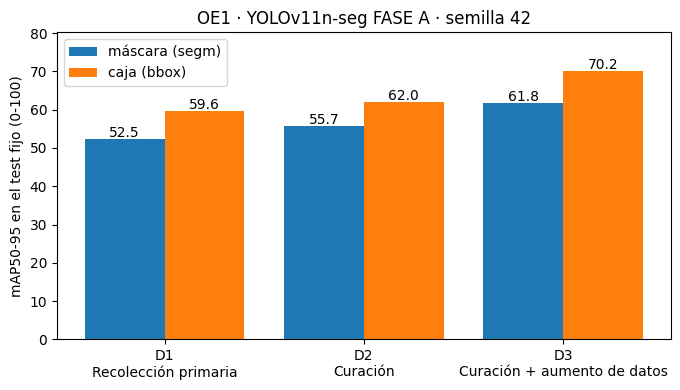


Tabla, gráfico y resumen guardados en /content/drive/MyDrive/tesis-rg6final/informe_para_codex/oe1


In [10]:
import pandas as pd
import matplotlib.pyplot as plt

filas = []
for nombre, v in VARIANTES.items():
    with open(os.path.join(SALIDA, nombre, "metricas_test.json"), encoding="utf-8") as f:
        m = json.load(f)
    filas.append({"variante": nombre, "estrategia": v["estrategia"], "datos": v["entrada"],
                  "aumento": "CommonAug A" if v["aumento"] else "ninguno",
                  "img_train": v["origen"]["imagenes"]["train"], "img_valid": v["origen"]["imagenes"]["valid"],
                  "img_test": v["origen"]["imagenes"]["test"],
                  "mAP50-95_segm": m["segm"]["AP"], "AP50_segm": m["segm"]["AP50"], "AP75_segm": m["segm"]["AP75"],
                  "mAP50-95_bbox": m["bbox"]["AP"], "AP50_bbox": m["bbox"]["AP50"],
                  "AP_segm_rg6Bien": m["segm_por_clase"]["rg6Bien"]["AP"],
                  "AP_segm_rg6Mal": m["segm_por_clase"]["rg6Mal"]["AP"]})
tabla = pd.DataFrame(filas).round(2)
print(tabla.to_string(index=False))

por = tabla.set_index("variante")
metricas_efecto = ["mAP50-95_segm", "AP50_segm", "mAP50-95_bbox", "AP_segm_rg6Bien", "AP_segm_rg6Mal"]
efectos = pd.DataFrame([
    {"comparacion": "D2 - D1 (curación)", **{c: por.loc["D2", c] - por.loc["D1", c] for c in metricas_efecto}},
    {"comparacion": "D3 - D2 (aumento)", **{c: por.loc["D3", c] - por.loc["D2", c] for c in metricas_efecto}},
]).round(2)
print("\nEfectos (puntos de mAP):")
print(efectos.to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(tabla))
ax.bar(x - 0.2, tabla["mAP50-95_segm"], 0.4, label="máscara (segm)")
ax.bar(x + 0.2, tabla["mAP50-95_bbox"], 0.4, label="caja (bbox)")
for i, (s, b) in enumerate(zip(tabla["mAP50-95_segm"], tabla["mAP50-95_bbox"])):
    ax.text(i - 0.2, s + 0.5, f"{s:.1f}", ha="center"); ax.text(i + 0.2, b + 0.5, f"{b:.1f}", ha="center")
ax.set_xticks(x, [f"{r.variante}\n{r.estrategia}" for r in tabla.itertuples()])
ax.set_ylabel("mAP50-95 en el test fijo (0-100)")
ax.set_title("OE1 · YOLOv11n-seg FASE A · semilla 42")
ax.set_ylim(0, max(tabla["mAP50-95_bbox"].max(), tabla["mAP50-95_segm"].max()) + 10)
ax.legend()
fig.tight_layout()

os.makedirs(INFORME, exist_ok=True)
for destino in [SALIDA, INFORME]:
    tabla.to_csv(os.path.join(destino, "tabla_oe1.csv"), index=False)
    efectos.to_csv(os.path.join(destino, "efectos_oe1.csv"), index=False)
    fig.savefig(os.path.join(destino, "grafico_oe1.png"), dpi=200)
plt.show()

def tabla_md(df):
    lineas = ["| " + " | ".join(df.columns) + " |", "|" + "---|" * len(df.columns)]
    lineas += ["| " + " | ".join(str(x) for x in fila) + " |" for fila in df.itertuples(index=False)]
    return "\n".join(lineas)

for nombre in VARIANTES:
    shutil.copy2(os.path.join(SALIDA, nombre, "entrenamiento", "results.csv"),
                 os.path.join(INFORME, f"curvas_entrenamiento_{nombre}.csv"))

resumen = f'''# OE1 · Comparación de estrategias de construcción del dataset

**Pregunta:** qué estrategia (recolección primaria, curación, aumento de datos) produce el dataset más adecuado.

**Diseño:** mismo modelo (YOLOv11n-seg), misma receta (FASE A del OE2: 50 épocas, imgsz 1024, batch 16,
optimizador auto = AdamW lr 0.001667, cos_lr, patience 30) y semilla 42. Solo cambia el dataset o el aumento.
Las tres variantes se evalúan en el **mismo test fijo** ({tabla['img_test'][0]} fotos) con pycocotools
(conf 0.001, max_det 300, imgsz 1024, máscaras RLE a resolución original; AP en escala 0-100).

- D1 = data_roboflow (sin curar), estratificado con el test fijo apartado, sin aumento.
- D2 = data_curado (data_roboflow + 62 fotos añadidas para balancear rg6Bien/rg6Mal), estratificado 70/20/10, sin aumento.
- D3 = D2 + aumento CommonAug A (hsv 0.015/0.4/0.4, rotación ±5°, volteo horizontal 0.5).

## Resultados en el test fijo

{tabla_md(tabla)}

## Efectos (puntos de mAP)

{tabla_md(efectos)}

**Limitación:** una sola semilla; diferencias menores a ~1 punto deben leerse como indicativas.

Archivos: tabla_oe1.csv, efectos_oe1.csv, grafico_oe1.png, curvas_entrenamiento_D*.csv y, por carpeta
data_estratificadoN/, resumen_estratificacion.csv (reparto y balance de clases), duplicados.json y origen.json.
Resultados completos (pesos, predicciones, manifiestos): resultados/oe1/.
'''
with open(os.path.join(INFORME, "resumen.md"), "w", encoding="utf-8") as f:
    f.write(resumen)
print("\nTabla, gráfico y resumen guardados en", INFORME)